# Guía práctica 4

## Ejercicio 5 - Chirp y ventanas

Tres sinusoides de frecuencias similares. Dos tienen amplitud parecida y la
tercera es más chica.

In [19]:
from matplotlib.pyplot import show, subplots, tight_layout
from numpy import abs, arange, hamming, linspace, log10, maximum, ones
from numpy.fft import fft
from scipy.io import loadmat
from scipy.signal import find_peaks, zoom_fft

In [20]:
x = loadmat("sinusoides_practica4.mat")["x"].squeeze()

sampling_period_s = 1.0
sampling_freq_hz = 1 / sampling_period_s
n_samples = x.size
freq_resolution_hz = sampling_freq_hz / n_samples

print(f"N  = {n_samples}")
print(f"fs = {sampling_freq_hz} Hz")
print(f"df = {freq_resolution_hz:.3e} Hz")
print(f"duracion = {n_samples * sampling_period_s:.0f} s")

N  = 2048
fs = 1.0 Hz
df = 4.883e-04 Hz
duracion = 2048 s


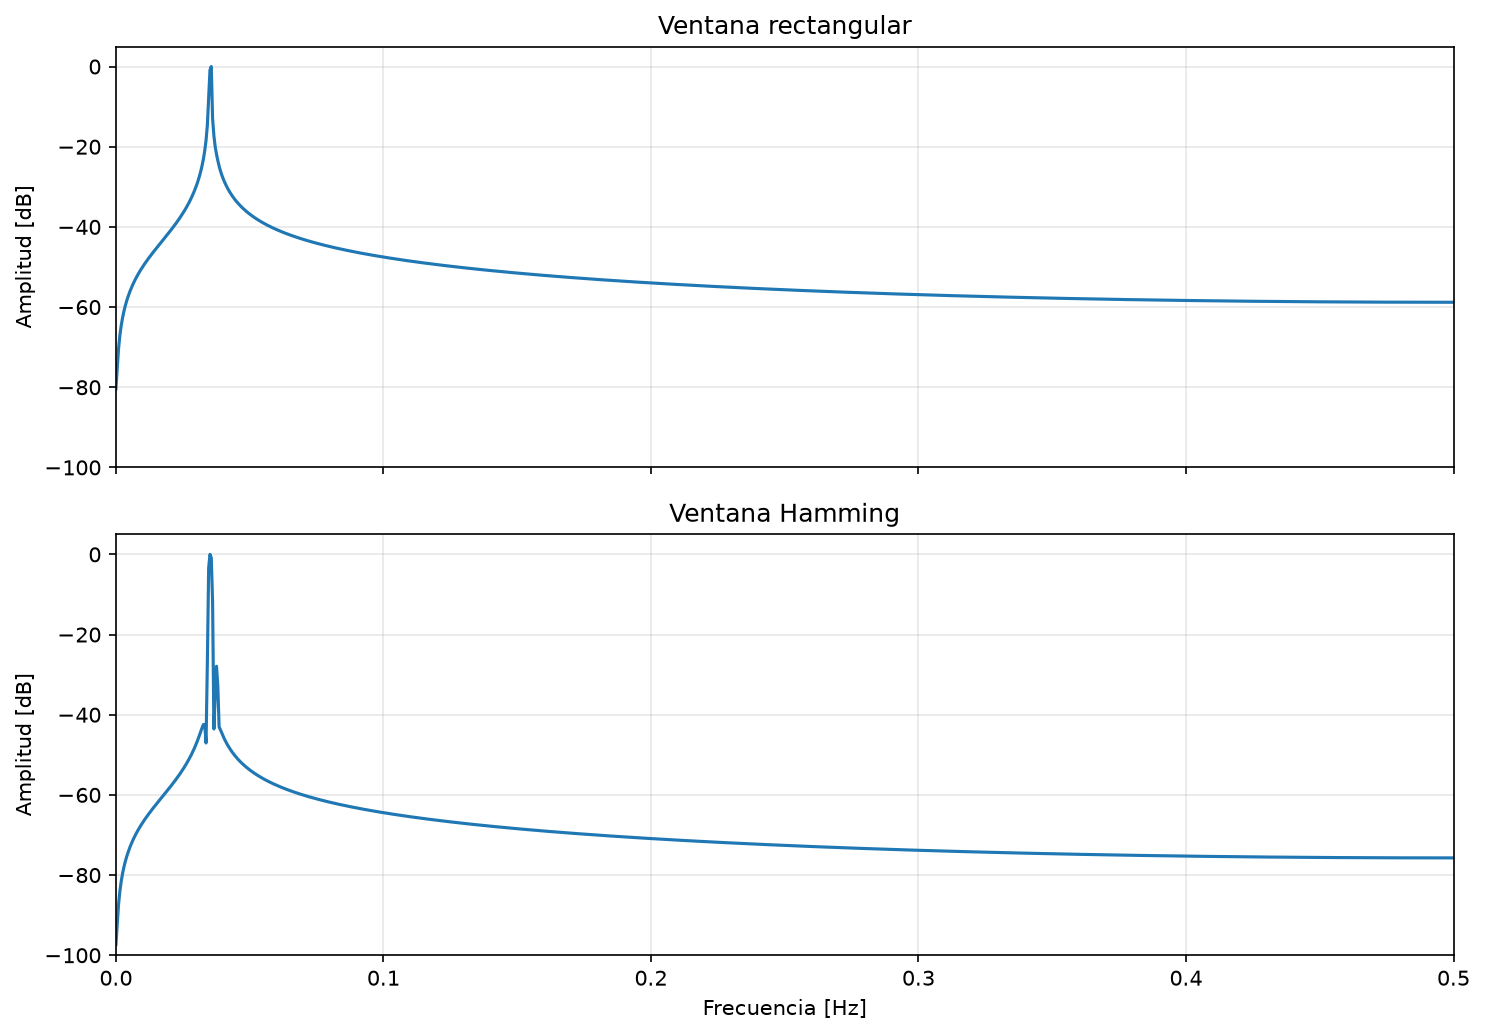

In [21]:
def spectrum_db(x, w):
    X = abs(fft(x * w))
    return 20 * log10(maximum(X, 1e-12) / X.max())


f = arange(n_samples) * freq_resolution_hz
windows = [("rectangular", ones(n_samples)), ("Hamming", hamming(n_samples))]

fig, axes = subplots(2, 1, figsize=(10, 7), dpi=150, sharex=True, sharey=True)

for ax, (name, w) in zip(axes, windows):
    ax.plot(f, spectrum_db(x, w))
    ax.set_title(f"Ventana {name}")
    ax.set_ylabel("Amplitud [dB]")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Frecuencia [Hz]")
axes[-1].set_xlim(0, sampling_freq_hz / 2)
axes[-1].set_ylim(-100, 5)
tight_layout()
show()

Zoom a la zona donde está todo.

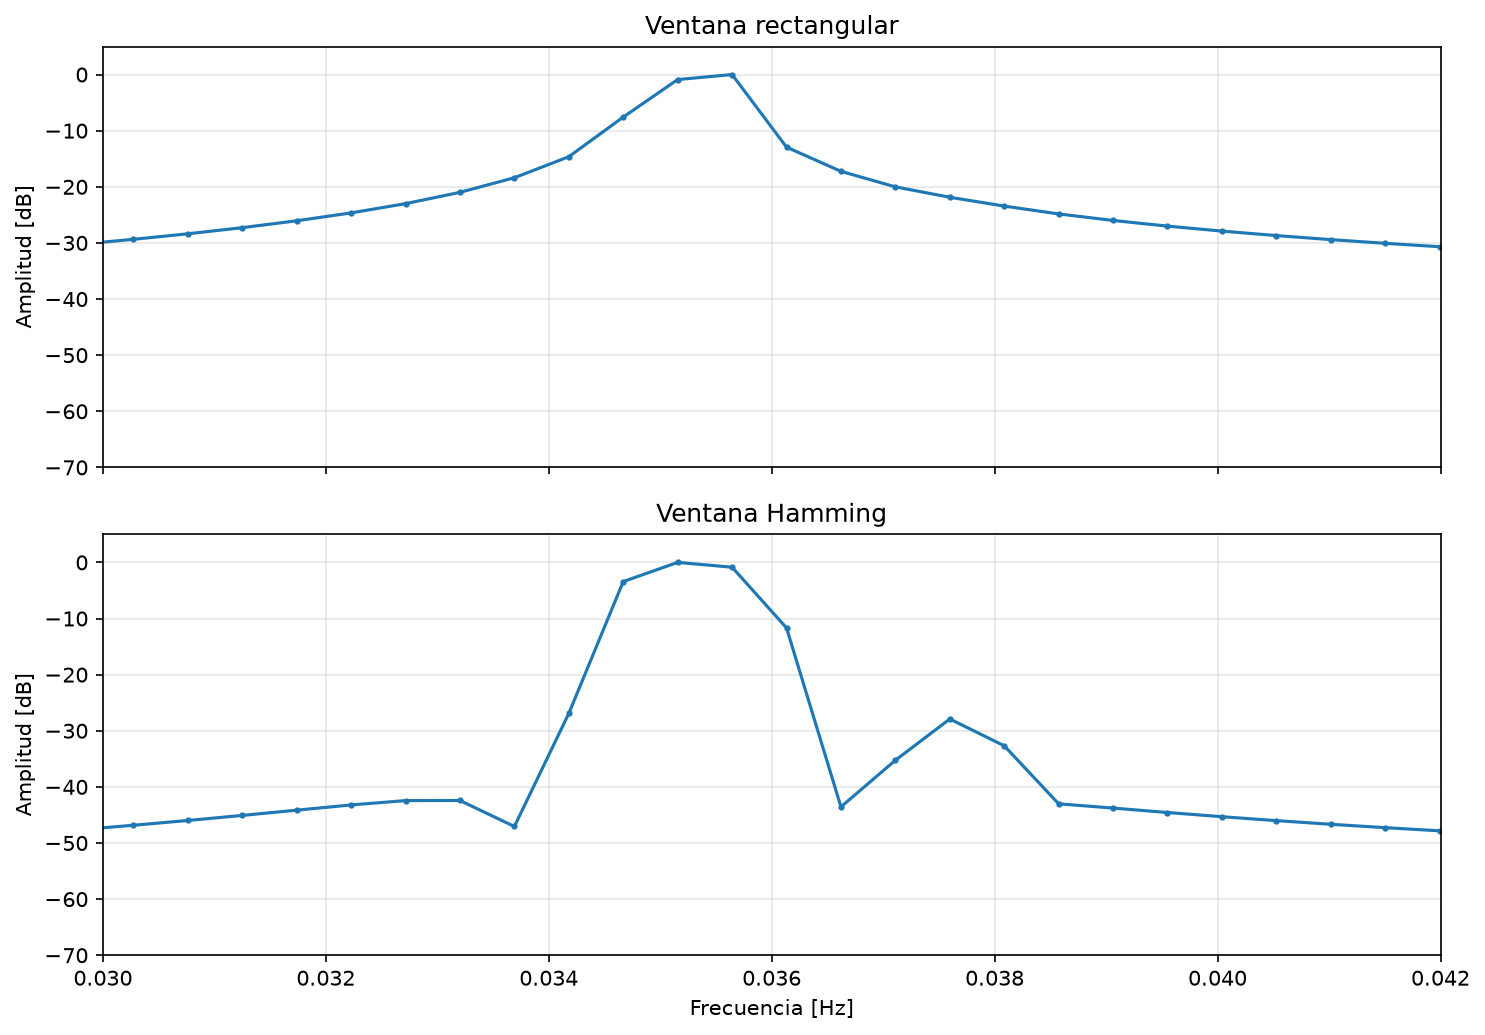

In [22]:
fig, axes = subplots(2, 1, figsize=(10, 7), dpi=150, sharex=True, sharey=True)

for ax, (name, w) in zip(axes, windows):
    ax.plot(f, spectrum_db(x, w), marker=".", markersize=4)
    ax.set_title(f"Ventana {name}")
    ax.set_ylabel("Amplitud [dB]")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Frecuencia [Hz]")
axes[-1].set_xlim(0.030, 0.042)
axes[-1].set_ylim(-70, 5)
tight_layout()
show()

### a) Estimación de frecuencias y amplitudes

Con ventana rectangular se ven dos picos juntos cerca de 0.035 Hz, pero no
aparece el tercero. Con Hamming aparece el tercero en 0.0376 Hz, pero los dos
juntos se fusionan en uno. Ninguna de las dos ventanas sola muestra las tres sinusoides, así que hay que combinar las dos mediciones.

### b) Transformada chirp

La TDF evalúa la transformada Z en $N$ puntos equiespaciados del círculo
unitario. La chirp la evalúa en $M$ puntos de un arco que uno elige, así que
sirve para hacer zoom en una banda angosta con muchos más puntos. Uso
`scipy.signal.zoom_fft`, que es la chirp con el rango de frecuencias como
parámetro.

In [23]:
def czt_zoom(x, w, freq_start_hz, freq_stop_hz, n_points):
    # zoom_fft evaluates the transform on n_points of the band, instead of the
    # fixed bins of the FFT. Normalised by the window gain so the peaks read
    # the amplitude of each sinusoid.
    amplitude = abs(
        zoom_fft(x * w, [freq_start_hz, freq_stop_hz], m=n_points, fs=sampling_freq_hz)
    ) / (w.sum() / 2)
    f = linspace(freq_start_hz, freq_stop_hz, n_points, endpoint=False)
    return f, amplitude

--- rectangular
    f = 0.033826 Hz   A = 0.1696   ( -15.7 dB)
    f = 0.034323 Hz   A = 0.2718   ( -11.6 dB)
    f = 0.034983 Hz   A = 1.0287   (   0.0 dB)
    f = 0.035578 Hz   A = 0.9696   (  -0.5 dB)
    f = 0.036230 Hz   A = 0.2661   ( -11.7 dB)
--- Hamming
    f = 0.033322 Hz   A = 0.0104   ( -39.5 dB)
    f = 0.035062 Hz   A = 0.9830   (   0.0 dB)
    f = 0.037608 Hz   A = 0.0392   ( -28.0 dB)
    f = 0.038684 Hz   A = 0.0091   ( -40.7 dB)
    f = 0.039169 Hz   A = 0.0081   ( -41.6 dB)


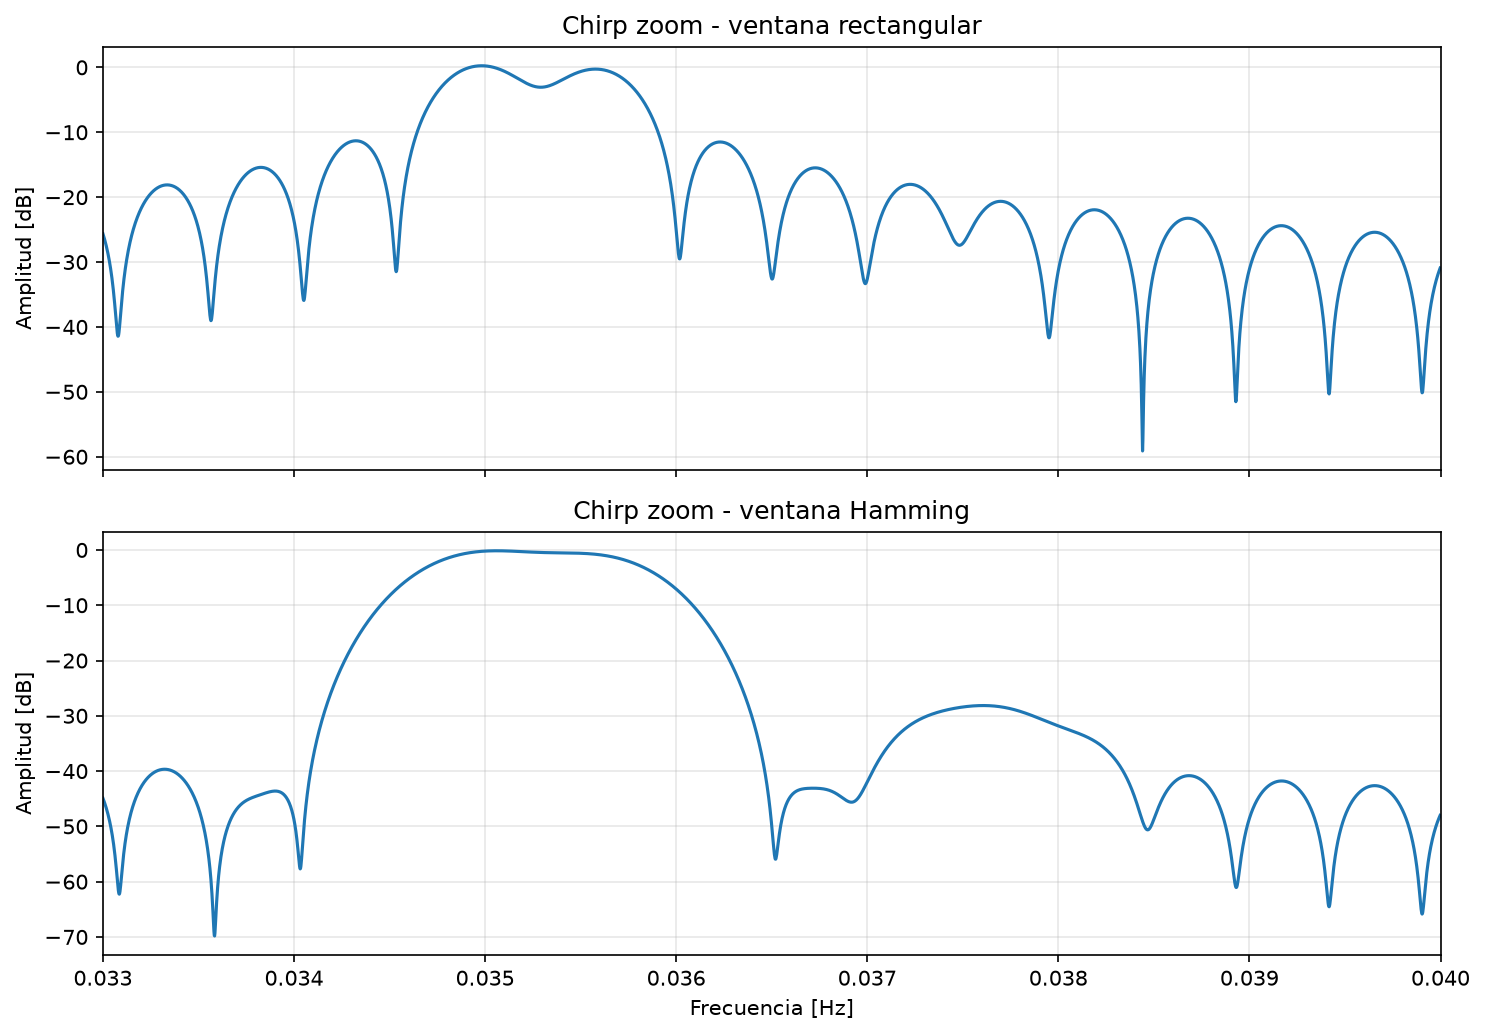

In [ ]:
ZOOM_START_HZ = 0.033
ZOOM_STOP_HZ = 0.040
ZOOM_POINTS = 4000

fig, axes = subplots(2, 1, figsize=(10, 7), dpi=150, sharex=True)

for ax, (name, w) in zip(axes, windows):
    f_zoom, amplitude = czt_zoom(x, w, ZOOM_START_HZ, ZOOM_STOP_HZ, ZOOM_POINTS)
    ax.plot(f_zoom, 20 * log10(maximum(amplitude, 1e-12)))
    ax.set_title(f"Chirp zoom - ventana {name}")
    ax.set_ylabel("Amplitud [dB]")
    ax.grid(True, alpha=0.3)

    peaks, _ = find_peaks(amplitude)
    tallest = sorted(sorted(peaks, key=lambda i: amplitude[i])[-5:])

    print(f"--- {name}")
    for i in tallest:
        level_db = 20 * log10(amplitude[i] / amplitude.max())
        print(
            f"    f = {f_zoom[i]:.6f} Hz   A = {amplitude[i]:.4f}   ({level_db:6.1f} dB)"
        )

axes[-1].set_xlabel("Frecuencia [Hz]")
axes[-1].set_xlim(ZOOM_START_HZ, ZOOM_STOP_HZ)
tight_layout()
show()

Los picos de $-11.6$ dB del panel rectangular son lóbulos laterales: están
simétricos a los lados del par central y no aparecen con Hamming.

Estimación final:

| | frecuencia | amplitud |
|---|---|---|
| 1 | 0.03498 Hz | 1.03 |
| 2 | 0.03558 Hz | 0.97 |
| 3 | 0.03761 Hz | 0.039 |

Las dos primeras salen de la rectangular y la tercera de Hamming. El chirp sirvió
para ubicar los picos con más precisión: con los bins de la TDF el primero caía
en 0.035156 Hz.

### c) Largo de registro necesario

Los dos tonos juntos están separados por

$$f_2 - f_1 = 0.0355776 - 0.0349821 = 5.955 \times 10^{-4}\ \text{Hz}$$

que son 1.22 bins. Para separarlos, el lóbulo principal de la ventana tiene que
entrar en esa separación:

$$T_{\text{registro}} \ge \frac{L}{f_2 - f_1}$$

con $L$ el ancho del lóbulo principal en bins.

In [25]:
freq_1_hz = 0.0349821
freq_2_hz = 0.0355776
separation_hz = freq_2_hz - freq_1_hz

# Hamming: main lobe 2 bins wide, sidelobes at -43 dB.
HAMMING_MAIN_LOBE_BINS = 2
min_duration_s = HAMMING_MAIN_LOBE_BINS / separation_hz

print(
    f"f2 - f1 = {separation_hz:.3e} Hz = {separation_hz / freq_resolution_hz:.2f} bins"
)
print(f"T minimo con Hamming = {min_duration_s:.0f} s")

f2 - f1 = 5.955e-04 Hz = 1.22 bins
T minimo con Hamming = 3359 s


Propongo usar la ventana de Hamming dado que sus lóbulos laterales están en $-43$ dB, bien
por debajo de los $-28$ dB del tono chico, así que lo deja ver. Con lóbulo
principal de 2 bins necesita 3359 s de registro, o sea 3359 muestras porque
$T_s = 1$ s. Redondeando a la potencia de 2 siguiente, **$N = 4096$**.

El registro actual de 2048 muestras no alcanza, y por eso Hamming fusionaba los
dos picos juntos. Esto no se arregla ni con otra ventana ni con el chirp, sino
midiendo más tiempo: la resolución es $\Delta f = 1/T_{\text{registro}}$.